# RehaPiano, week 3: age, weakly used hands and tremor of individual fingers

**Task (sheet column F):**
1. basic statistics comparing people by age (histogram in 10-year groups), healthy vs sick;
2. how many sick participants barely use one hand;
3. a proposal for analysing tremor finger by finger: do some fingers shake more than others, and do fingers differ within one person?

**Data:** the Balanced Force game (`EXACT_FORCE`). The participant holds a steady force with all ten fingers; each attempt lasts about 16 s and the 3–15 s part is analysed. Every finger of every attempt is processed separately and averaged up to one value per person (attempt → session → person), so **one person is always one statistical unit**.

**Source of the numbers:** the per-finger pipeline in `src/rehapiano` (D. Sholtys; tables in `outputs/`) and the questionnaire screening from week 2. The Slovak notebook `analyza_prstov.ipynb` in this folder is the original version; this notebook is an independent English version that changes the points listed at the end.

> This is an exploratory analysis of research data. "Sick" means recruited into the patient cohort; it is not a diagnosis, and nothing here is a clinical test.

## Who is healthy and who is sick?

| Label used here | Who | People |
|---|---|---|
| **Healthy group** | control participants whose questionnaire reports no condition affecting hand strength or coordination | 76 |
| **Sick group** | participants recruited into the patient cohort (exact diagnoses are not available) | 48 |
| *Other controls* | controls reporting a relevant condition (11), without a usable questionnaire (2) or with a duplicated questionnaire ID (1) | 14 |

The 14 *other controls* are shown in the age table but left out of every healthy-vs-sick comparison: they are not confirmed healthy examples. Blue always means healthy and orange always means sick.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

import week3_analysis as w3

R = w3.run()  # recomputes every table and figure in ~5 s from the pipeline outputs
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 20)


def figure(name):
    display(Image(filename=str(w3.FIG / f"{name}.png")))


def say(text):
    display(Markdown(text))

## 1. Age: healthy vs sick

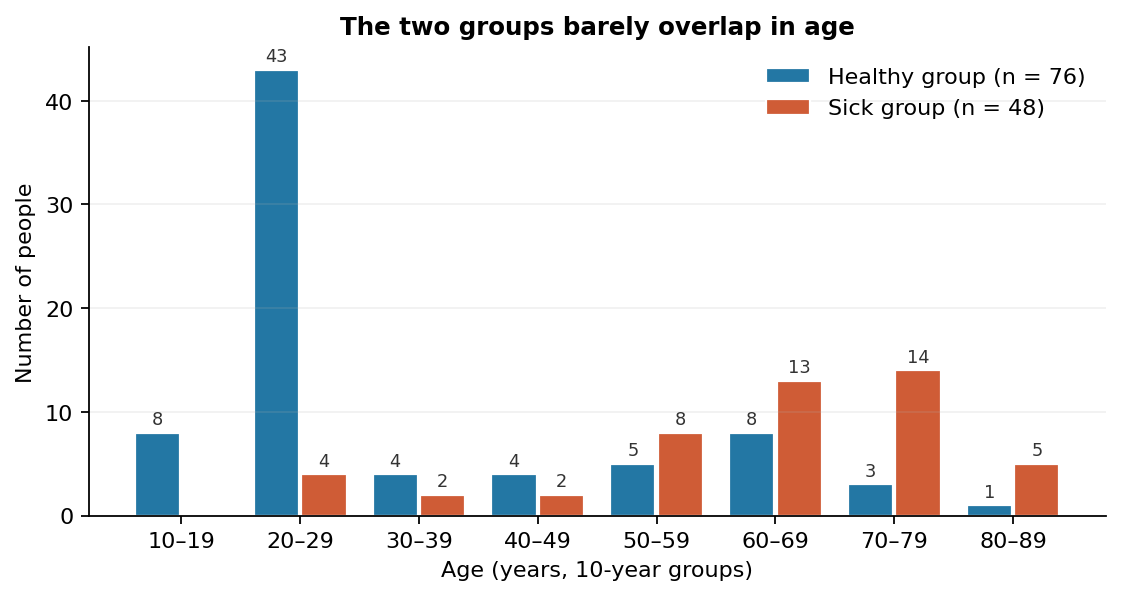

,People,Median age,Q1,Q3,Youngest,Oldest,Aged 50+,Female,Male,Handedness recorded,Recording period
Group,,,,,,,,,,,
Healthy,76,23.0,21.00,43.50,18,85,17,25,51,76,"Feb 2025, Sep 2026"
Sick,48,66.5,56.00,74.25,21,89,40,20,28,0,Mar-Aug 2025
Other control,14,46.0,22.75,65.75,21,83,7,11,3,14,"Feb 2025, Sep 2026"


**The groups differ strongly in age:** median 23 years (healthy) vs 66.5 years (sick); Mann–Whitney p = 3.0e-11, rank-biserial r = 0.71 (1 would mean every sick person is older than every healthy person). Only **17 healthy people are aged 50 or more**, against 40 sick people. The gender split does not differ clearly (chi-square p = 0.42).

In [2]:
figure("01_age_histogram")
display(R["age_summary"].set_index("Group"))
t = R["age_test"].iloc[0]
s = R["age_summary"].set_index("Group")
say(f"**The groups differ strongly in age:** median {s.loc['Healthy', 'Median age']:.0f} years (healthy) vs "
    f"{s.loc['Sick', 'Median age']:.1f} years (sick); Mann–Whitney p = {t['p']:.1e}, rank-biserial r = {t['effect_r']:.2f} "
    f"(1 would mean every sick person is older than every healthy person). "
    f"Only **{s.loc['Healthy', 'Aged 50+']} healthy people are aged 50 or more**, against {s.loc['Sick', 'Aged 50+']} sick people. "
    f"The gender split does not differ clearly (chi-square p = {R['gender_p']:.2f}).")

In [3]:
groups = R["age_groups"].set_index("Age group")
display(groups.style.format({"Healthy %": "{:.1f}", "Sick %": "{:.1f}"}))

label,Healthy,Sick,Other control,Healthy %,Sick %
Age group,,,,,
10-19,8,0,0,10.5,0.0
20-29,43,4,5,56.6,8.3
30-39,4,2,2,5.3,4.2
40-49,4,2,0,5.3,4.2
50-59,5,8,1,6.6,16.7
60-69,8,13,3,10.5,27.1
70-79,3,14,2,3.9,29.2
80-89,1,5,1,1.3,10.4


**What this means for everything that follows.** Most healthy participants are students in their twenties recorded in February 2025; the older healthy participants come partly from the same session and partly from a second session in September 2026; the sick participants were recorded between March and August 2025, with a different game-step identifier. Any healthy-vs-sick difference may therefore come from **age, recording period or protocol** as well as from the illness. Where a comparison could be distorted by age, it is repeated for people aged 50+ only. Handedness is recorded for controls but missing for every sick participant.

## 2. Sick participants who barely use one hand

**Measure.** For each person: average force of the five fingers of each hand (3–15 s, averaged over attempts), then

$$\text{hand symmetry} = \frac{\text{force of the weaker hand}}{\text{force of the stronger hand}}$$

1 means both hands press equally; 0 means one hand does not press at all. Force is in uncalibrated device units, which cancel in the ratio.

**Rule.** There is no agreed clinical cut-off, so the healthy group is the yardstick: a hand counts as *barely used* when the person's symmetry is lower than in 97.5 % of healthy people. Fixed cut-offs are reported as well.

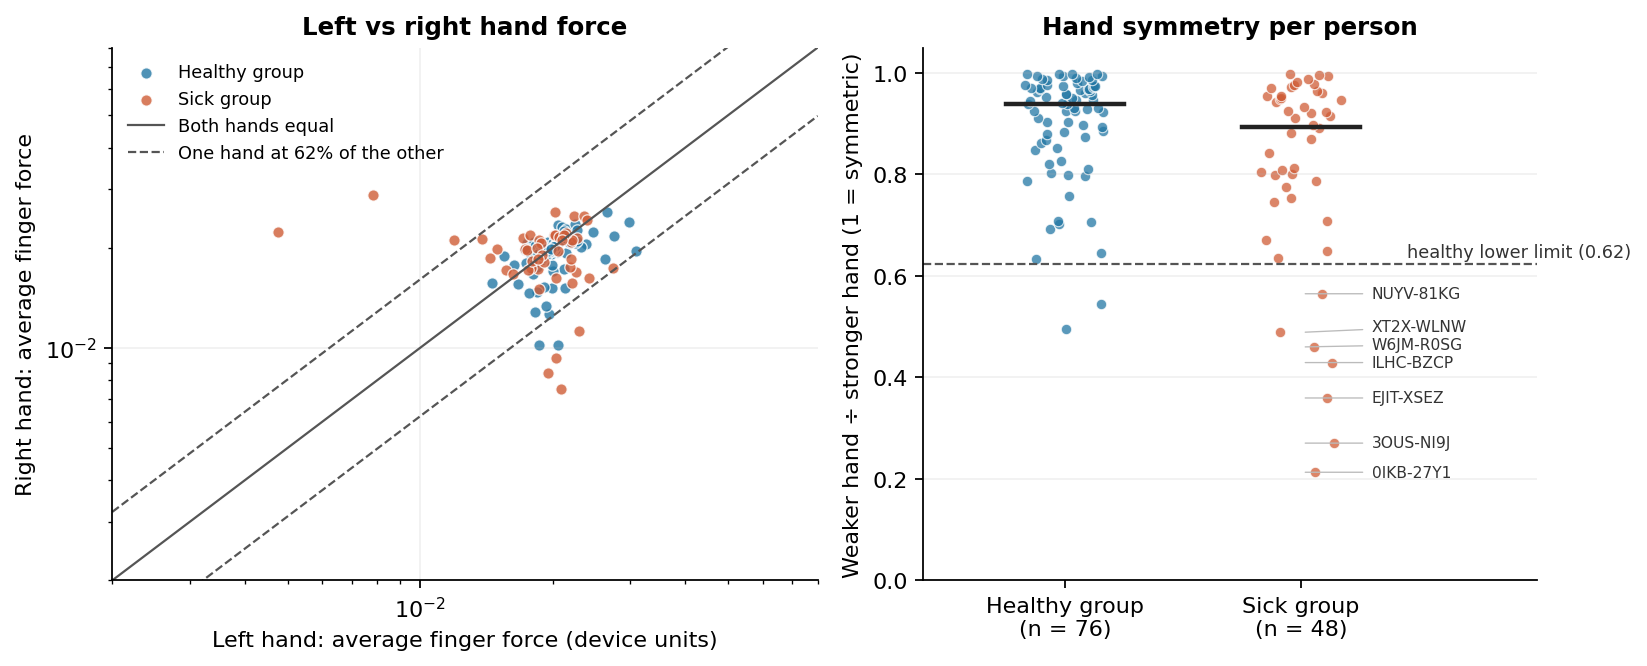

,Healthy: people below,Healthy: % below,Sick: people below,Sick: % below
Rule,,,,
ratio < 0.10,0,0.0,0,0.0
ratio < 0.25,0,0.0,1,2.1
ratio < 0.50,1,1.3,6,12.5
ratio < 0.623 (healthy 2.5th percentile),2,2.6,7,14.6


**Answer: 7 of 48 sick participants (15 %)** press with one hand less than 62% as hard as with the other, which only 2 of 76 healthy people do (about 2 are expected by the way the limit is defined). The limit itself is uncertain because it rests on the two or three most asymmetric healthy people; re-estimating it on resampled healthy groups gives **6–10 sick participants** (95 % range). **No one has a completely silent hand** (symmetry < 0.10: 0 sick participants).

In [4]:
figure("02_hand_symmetry")
c = R["weak_hand_checks"]
display(R["weak_hand_counts"].set_index("Rule").style.format("{:.1f}", subset=["Healthy: % below", "Sick: % below"]))
lo, hi = c["sick_below_bootstrap_95"]
say(f"**Answer: {c['sick_below']} of {c['n_sick']} sick participants ({100 * c['sick_below'] / c['n_sick']:.0f} %)** press with one hand "
    f"less than {c['threshold']:.0%} as hard as with the other, which only {c['healthy_below']} of {c['n_healthy']} healthy people do "
    f"(about 2 are expected by the way the limit is defined). The limit itself is uncertain because it rests on the two or three "
    f"most asymmetric healthy people; re-estimating it on resampled healthy groups gives **{lo}–{hi} sick participants** (95 % range). "
    f"**No one has a completely silent hand** (symmetry < 0.10: {c['sick_below_010']} sick participants).")

In [5]:
display(R["weak_hand_people"].rename(columns={
    "patient_id": "ID", "label": "Group", "age": "Age", "weaker_hand": "Weaker hand", "force_ratio": "Hand symmetry",
    "fluctuation_ratio": "Oscillation symmetry", "left_mean_force": "Left force", "right_mean_force": "Right force",
    "inactive_fingers_weaker_hand": "Inactive fingers (weaker hand)",
    "week2_low_use_windows": "Week-2 low-use windows"}).set_index("ID"))

,Group,Age,Weaker hand,Hand symmetry,Oscillation symmetry,Left force,Right force,Inactive fingers (weaker hand),Week-2 low-use windows
ID,,,,,,,,,
1302202521,Healthy,23,right,0.495,0.799,0.021,0.010,3,0
1302202522,Healthy,23,right,0.545,0.766,0.019,0.010,2,0
0IKB-27Y1,Sick,75,left,0.213,0.138,0.005,0.022,1,0
3OUS-NI9J,Sick,82,left,0.270,0.264,0.008,0.029,1,1
EJIT-XSEZ,Sick,76,right,0.359,0.721,0.021,0.008,1,0
ILHC-BZCP,Sick,73,right,0.429,0.392,0.020,0.008,1,0
W6JM-R0SG,Sick,58,right,0.460,0.574,0.020,0.009,0,0
XT2X-WLNW,Sick,67,right,0.489,0.708,0.023,0.011,0,1
NUYV-81KG,Sick,88,left,0.565,0.609,0.012,0.021,1,0


*Oscillation symmetry* is the same ratio computed from the 4–15 Hz oscillation amplitude instead of force. When both ratios are low (0IKB-27Y1, 3OUS-NI9J), the weaker hand neither presses nor makes the small corrections a controlling hand makes. *Week-2 low-use windows* counts the 5 s windows that the week-2 screening flagged; it caught only 2 of these 7 people, so the week-2 window rule is too lenient to answer this question and the person-level symmetry is the better measure.

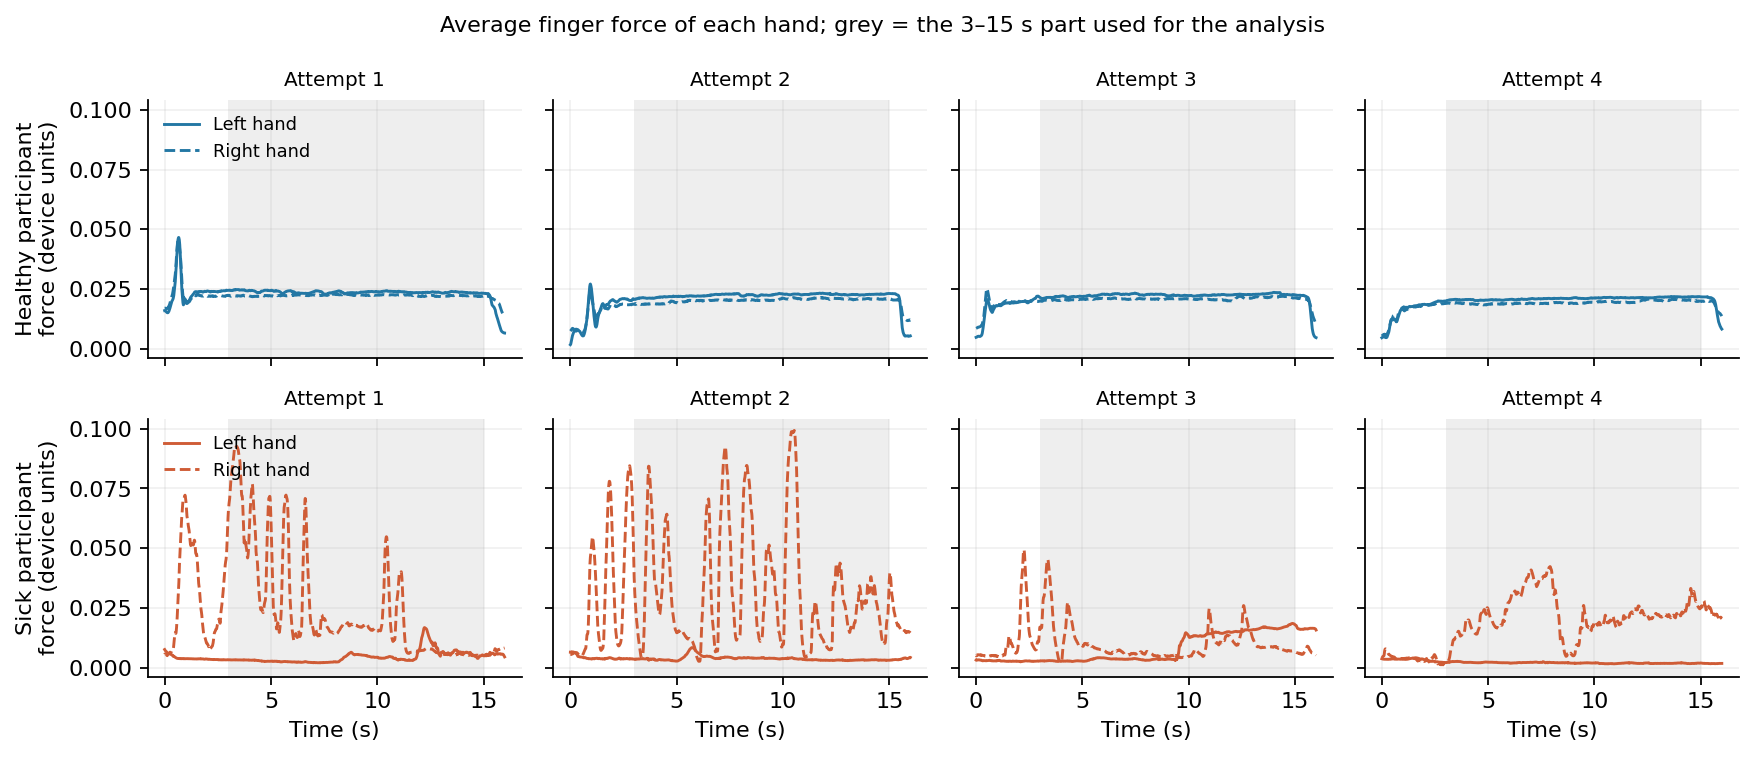

**Example.** Top: a typical healthy participant aged 61 (ID 1402202503, symmetry 0.92) holds both hands steady at the same level. Bottom: the most asymmetric sick participant, aged 75 (ID 0IKB-27Y1, symmetry 0.21). The left hand stays flat just above zero, which looks like a hand resting on the keys rather than pressing, and the right hand does not hold a steady force but pumps in large bursts. By the strict < 0.10 rule this hand is 'used', yet in practice this person plays with one hand.

In [6]:
figure("03_weak_hand_example")
e = R["weak_hand_example_ids"]
say(f"**Example.** Top: a typical healthy participant aged {e['healthy_age']} (ID {e['Healthy']}, symmetry {e['healthy_ratio']:.2f}) holds "
    f"both hands steady at the same level. Bottom: the most asymmetric sick participant, aged {e['sick_age']} "
    f"(ID {e['Sick']}, symmetry {e['sick_ratio']:.2f}). The left hand stays flat just above zero, which looks like a hand resting "
    f"on the keys rather than pressing, and the right hand does not hold a steady force but pumps in large bursts. "
    f"By the strict < 0.10 rule this hand is 'used', yet in practice this person plays with one hand.")

In [7]:
say(f"**Checks.** Symmetry does not depend on age among healthy people (Spearman ρ = {c['age_rho_healthy']:.2f}, "
    f"p = {c['age_p_healthy']:.2f}), so using healthy people of all ages as the yardstick is fair. Over the whole groups, "
    f"sick participants are somewhat less symmetric (median {c['group_test']['median_b']:.2f} vs {c['group_test']['median_a']:.2f}, "
    f"p = {c['group_test']['p']:.3f}). Among healthy people the hand that presses less is not simply the non-writing hand:")
display(R["weak_hand_dominance"].set_index("Writing hand (questionnaire)"))
say("Handedness is missing for the sick group, so we cannot tell whether a sick person's weaker hand is the affected side "
    "or just the non-dominant one.")

**Checks.** Symmetry does not depend on age among healthy people (Spearman ρ = -0.07, p = 0.57), so using healthy people of all ages as the yardstick is fair. Over the whole groups, sick participants are somewhat less symmetric (median 0.89 vs 0.94, p = 0.014). Among healthy people the hand that presses less is not simply the non-writing hand:

Hand that pressed less,left,right
Writing hand (questionnaire),,
left,4,7
right,28,37


Handedness is missing for the sick group, so we cannot tell whether a sick person's weaker hand is the affected side or just the non-dominant one.

## 3. Tremor of individual fingers

**Proposed analysis.** For every finger, attempt and hand separately: spectrogram of the 3–15 s force signal (5 s Hann windows), then the **average oscillation amplitude in the 4–15 Hz band** (`tremor_mean_amplitude`, device units). Slower changes (below 4 Hz) are treated as conscious force corrections. Fingers whose average force stays within the unloaded-sensor range (< 0.002) are marked *inactive*; their oscillation values describe sensor noise, so they are left out instead of being counted as "no tremor". Values are averaged over attempts and sessions to one value per person, hand and finger.

The analysis then asks five questions:

1. Is finger tremor measurable at all, i.e. larger than the sensor's own noise?
2. Do some fingers oscillate more than others, and is that just because they press harder?
3. Is every finger more tremulous in the sick group, or only some?
4. Could age explain the difference?
5. Within one person: is the increase local (a few fingers) or general (most fingers)?

The finger names assume sensor 1 = little finger … sensor 5 = thumb. This is not verified, but the force order supports it: sensor 5 presses about 7× harder than sensor 1, as a thumb would against a little finger.

### 3.1 Is finger tremor larger than sensor noise?

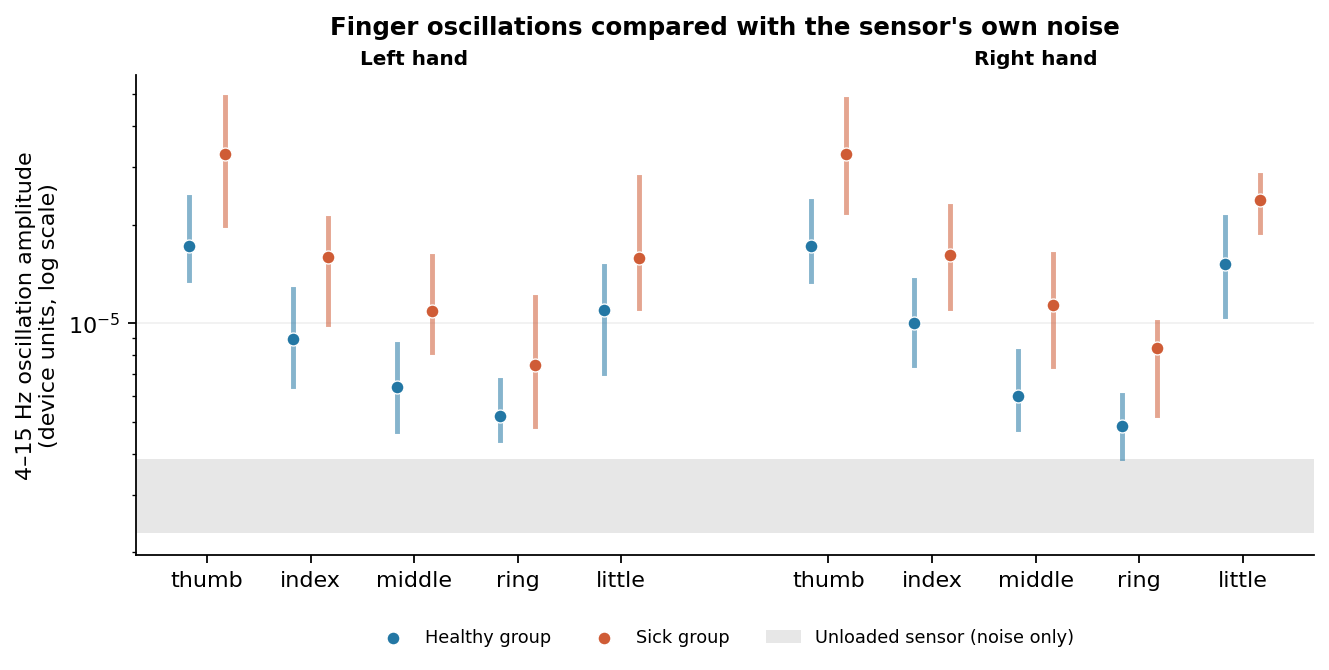

In [8]:
figure("04_finger_vs_noise")
noise = R["finger_noise"].copy()
noise["finger"] = noise["finger_name"]
display(noise.pivot_table(index=["label", "hand"], columns="finger", values="signal_to_noise")[w3.FINGERS]
        .style.format("{:.1f}").set_caption("Median amplitude ÷ unloaded-sensor noise"))
display(noise.pivot_table(index=["label", "hand"], columns="finger", values="percent_below_noise_p95")[w3.FINGERS]
        .style.format("{:.0f} %").set_caption("People whose finger is not above the noise level"))

The thumb, index and little finger are clearly above the noise (3–11× the noise level). **The ring and middle fingers are only 1.7–3.9× above it**, and for 9–24 % of healthy people their value is indistinguishable from noise. Conclusions about the ring and middle finger are therefore the least reliable.

### 3.2 Do some fingers oscillate more than others?

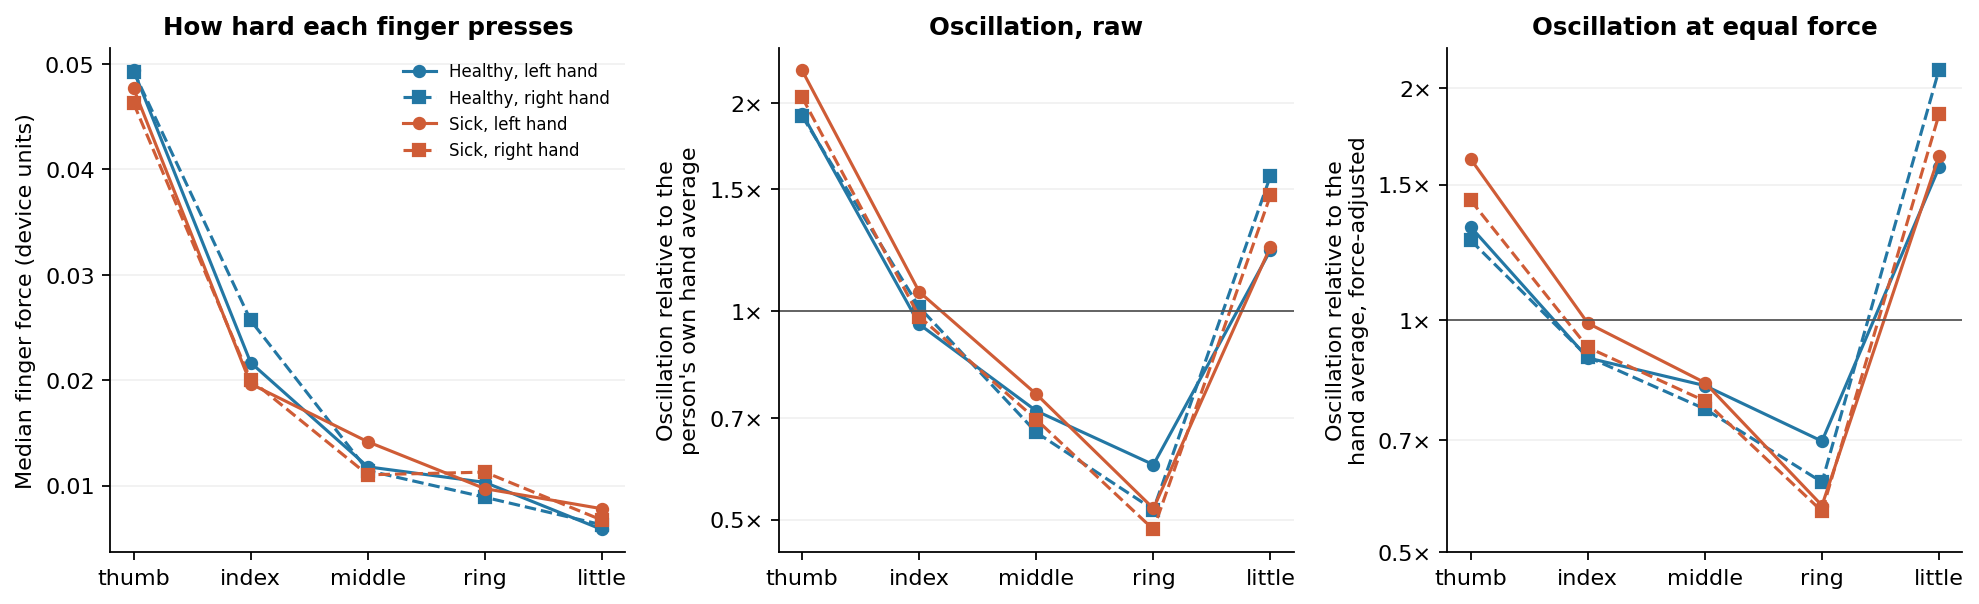

**Left panel:** the fingers press with very different force: thumb ≫ index > middle ≈ ring > little, the same in both groups. **Middle panel:** each finger's oscillation relative to the same person's hand average. The fingers clearly differ (Friedman test p < 1e-20 in every group and hand, Kendall's W 0.56–0.80, which means most people share the same order). But within a hand, a finger that presses harder also oscillates more (median within-hand Spearman ρ = 0.60). **Right panel:** the same comparison at equal force (amplitude grows about as force^0.33; this effect is removed using the within-hand relationship among healthy people). The ranking survives: the **little finger and the thumb oscillate most, the ring finger least**, in both groups. Each finger rests on its own sensor, so part of a 'finger' difference could also be a difference between sensors; the calibration recordings only cover unloaded sensors.

In [9]:
figure("05_finger_profiles")
f = R["finger_force_checks"]
fr = R["finger_profile_friedman"]
say(f"**Left panel:** the fingers press with very different force: thumb ≫ index > middle ≈ ring > little, the same in both groups. "
    f"**Middle panel:** each finger's oscillation relative to the same person's hand average. The fingers clearly differ "
    f"(Friedman test p < 1e-20 in every group and hand, Kendall's W {fr['kendall_w'].min():.2f}–{fr['kendall_w'].max():.2f}, "
    f"which means most people share the same order). But within a hand, a finger that presses harder also oscillates more "
    f"(median within-hand Spearman ρ = {f['rho_force_amplitude_median']:.2f}). "
    f"**Right panel:** the same comparison at equal force (amplitude grows about as force^{f['force_slope']:.2f}; this effect is "
    f"removed using the within-hand relationship among healthy people). The ranking survives: the **little finger and the thumb "
    f"oscillate most, the ring finger least**, in both groups. Each finger rests on its own sensor, so part of a 'finger' "
    f"difference could also be a difference between sensors; the calibration recordings only cover unloaded sensors.")

In [10]:
say(f"**A warning about the ratio measure.** The original analysis names the little finger as the most tremulous finger using "
    f"the ratio *fast oscillation ÷ slow movement*. That ratio falls steeply with force (median within-hand ρ = "
    f"{f['rho_force_ratio_median']:.2f}), and the finger with the highest ratio is the weakest-pressing finger in "
    f"{f['ratio_winner_is_weakest_finger']:.0%} of hands (20 % would be chance). The ratio therefore mostly answers "
    f"'which finger presses least'. The force-adjusted amplitude above gives the same top finger for a better reason.")
gt = R["finger_profile_group_tests"]
adj = gt.loc[(gt["measure"] == "profile_force_adjusted") & (gt["p_holm"] < .05)]
say("**Is the finger pattern different in the sick group?** Only slightly: the lines in the middle and right panels nearly "
    "overlap. After correcting for multiple tests (Holm), the force-adjusted pattern differs only for "
    + " and ".join(f"the {r.hand} {r.finger} (p {'< 0.001' if r.p_holm < .001 else f'= {r.p_holm:.3f}'}, {'higher' if r.effect_r > 0 else 'lower'} share in the sick group)"
                   for r in adj.itertuples())
    + ". The sick group's extra oscillation is spread over all fingers rather than concentrated in one.")

**A warning about the ratio measure.** The original analysis names the little finger as the most tremulous finger using the ratio *fast oscillation ÷ slow movement*. That ratio falls steeply with force (median within-hand ρ = -0.65), and the finger with the highest ratio is the weakest-pressing finger in 52% of hands (20 % would be chance). The ratio therefore mostly answers 'which finger presses least'. The force-adjusted amplitude above gives the same top finger for a better reason.

**Is the finger pattern different in the sick group?** Only slightly: the lines in the middle and right panels nearly overlap. After correcting for multiple tests (Holm), the force-adjusted pattern differs only for the left thumb (p = 0.011, higher share in the sick group) and the left ring (p < 0.001, lower share in the sick group). The sick group's extra oscillation is spread over all fingers rather than concentrated in one.

### 3.3 Sick vs healthy, finger by finger (people aged 50+)

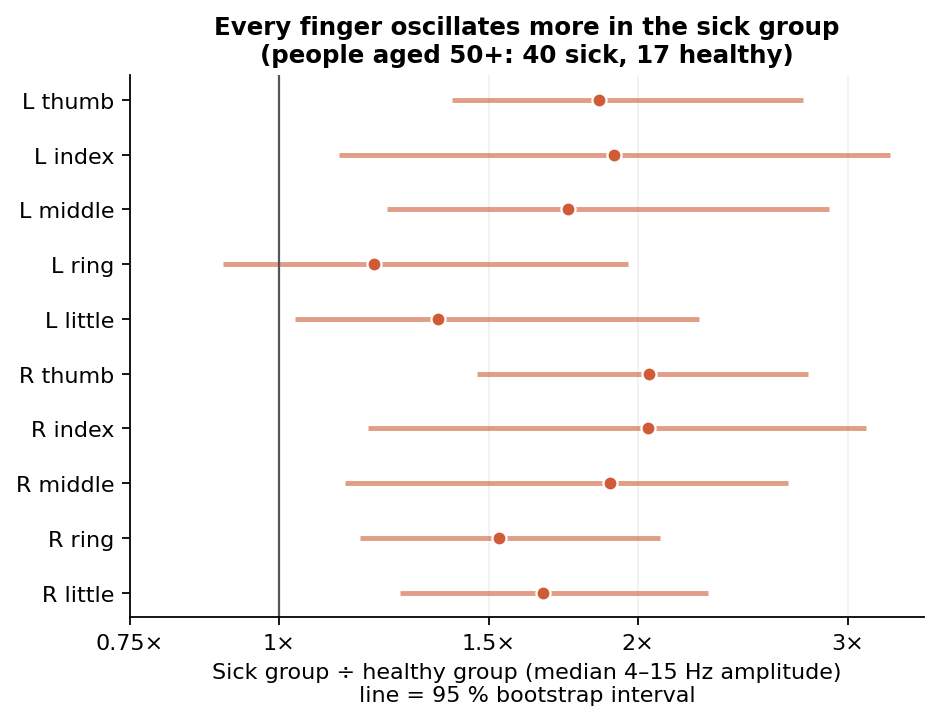

Sick ÷ healthy  95 % low  95 % high  Healthy n  Sick n  \
hand  finger                                                           
left  thumb            1.855     1.396      2.752         17      40   
      index            1.910     1.124      3.257         17      39   
      middle           1.748     1.231      2.892         16      40   
      ring             1.200     0.897      1.963         17      40   
      little           1.360     1.032      2.253         16      30   
right thumb            2.043     1.465      2.776         17      40   
      index            2.039     1.186      3.107         17      40   
      middle           1.897     1.136      2.675         16      40   
      ring             1.529     1.170      2.087         17      40   
      little           1.665     1.264      2.290         11      33   

                      p  p (Holm)  
hand  finger                       
left  thumb   7.417e-03     0.030  
      index   1.261e-02     0.038  
      middle  1.206e-03     0.010  
      ring    1.227e-01     0.123  
      little  1.404e-02     0.038  
right thumb   2.953e-04     0.003  
      index   2.622e-03     0.016  
      middle  1.868e-03     0.013  
      ring    2.776e-03     0.016  
      little  7.041e-04     0.006

Comparing only people aged 50+, the sick group's median 4–15 Hz amplitude is **1.2–2.0× the healthy value**; 9 of 10 fingers remain significant after correcting for 10 tests (the left ring finger, the noisiest sensor, does not). The healthy reference is small (17 people), which is why the intervals are wide.

In [11]:
figure("06_finger_group_ratio")
g = R["finger_group_ratio"]
display(g[["hand", "finger", "ratio_sick_to_healthy", "ci_low", "ci_high", "n_a", "n_b", "p", "p_holm"]]
        .rename(columns={"ratio_sick_to_healthy": "Sick ÷ healthy", "ci_low": "95 % low", "ci_high": "95 % high",
                         "n_a": "Healthy n", "n_b": "Sick n", "p_holm": "p (Holm)"}).set_index(["hand", "finger"]))
say(f"Comparing only people aged 50+, the sick group's median 4–15 Hz amplitude is **{g['ratio_sick_to_healthy'].min():.1f}–"
    f"{g['ratio_sick_to_healthy'].max():.1f}× the healthy value**; {int((g['p_holm'] < .05).sum())} of 10 fingers remain "
    f"significant after correcting for 10 tests (the left ring finger, the noisiest sensor, does not). The healthy reference "
    f"is small ({int(g['n_a'].max())} people), which is why the intervals are wide.")

### 3.4 Could age explain the difference?

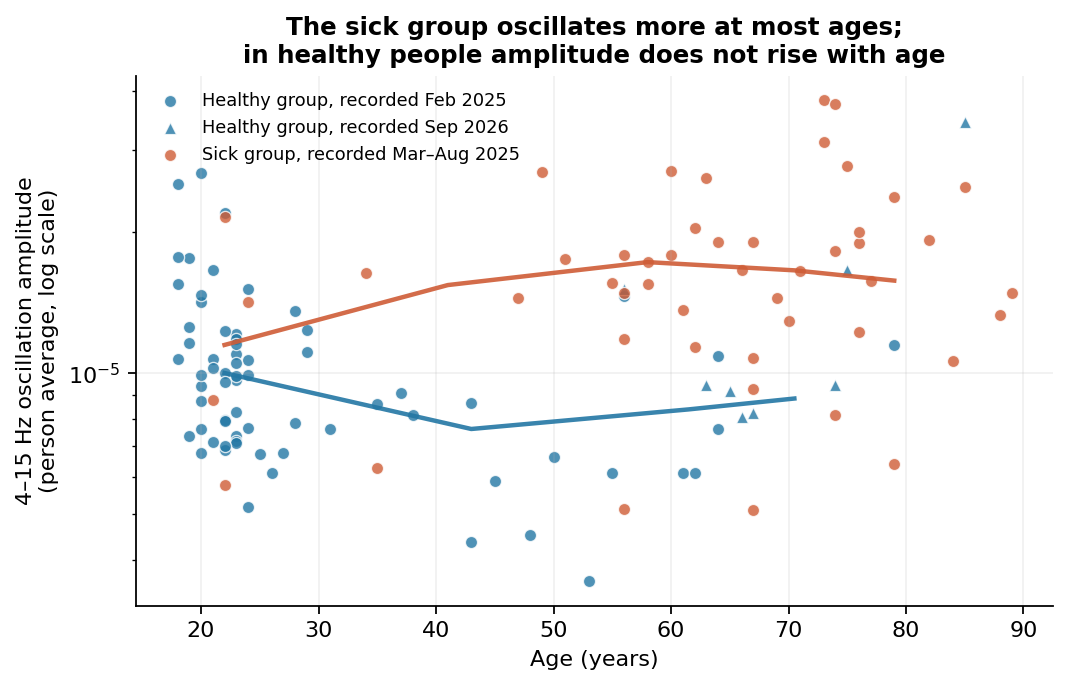

people  median_age  median_amplitude  rho_age_amplitude  \
label   batch                                                                   
Healthy Feb 2025          68        23.0         9.497e-06             -0.455   
        Sep 2026           8        66.5         9.437e-06              0.429   
Sick    Mar-Aug 2025      48        66.5         1.606e-05              0.180   
Healthy all               76        23.0         9.437e-06             -0.286   
Sick    all               48        66.5         1.606e-05              0.180   

                              p  
label   batch                    
Healthy Feb 2025      9.583e-05  
        Sep 2026      2.894e-01  
Sick    Mar-Aug 2025  2.220e-01  
Healthy all           1.231e-02  
Sick    all           2.220e-01

If the sick group oscillated more only because it is older, amplitude would rise with age among healthy people. It does not: in the February 2025 healthy session it falls with age (ρ = -0.46, p = 0.0001); in the small September 2026 session (8 people) there is no clear trend. The sick group is higher than the healthy group at most ages, including the few young sick participants. So **age alone does not explain the higher finger oscillation**. Recording period and game-step setup remain untested explanations, because they coincide with the groups. This also refines week 2: an age-only rule classified as well as the amplitude rule because age separates the groups, not because amplitude merely tracks age.

In [12]:
figure("07_age_vs_amplitude")
a = R["age_amplitude"]
display(a.set_index(["label", "batch"]))
fb = a.set_index(["label", "batch"]).loc[("Healthy", "Feb 2025")]
say(f"If the sick group oscillated more only because it is older, amplitude would rise with age among healthy people. It does "
    f"not: in the February 2025 healthy session it falls with age (ρ = {fb['rho_age_amplitude']:.2f}, p = {fb['p']:.4f}); in the small "
    f"September 2026 session (8 people) there is no clear trend. The sick group is higher than the healthy group at most ages, "
    f"including the few young sick participants. So **age alone does not explain the higher finger oscillation**. Recording "
    f"period and game-step setup remain untested explanations, because they coincide with the groups. This also refines week 2: "
    f"an age-only rule classified as well as the amplitude rule because age separates the groups, not because amplitude merely "
    f"tracks age.")

### 3.5 Within one person: local or general increase?

In [13]:
pc = R["tremor_pattern_counts"].set_index("Pattern")
display(pc)
say(f"Each finger is scored against healthy people aged 50+ (robust z-score of the log amplitude; a healthy person is never "
    f"compared with themselves). A finger counts as *elevated* above z = {w3.ELEVATED_Z} (higher than about 97.5 % of healthy "
    f"people). Among people aged 50+, **{pc.loc['none', 'Healthy']} of {pc['Healthy'].sum()} healthy people show no pattern**, "
    f"while {pc.loc['localized (2–4 fingers)', 'Sick']} sick participants have a localized and "
    f"{pc.loc['generalized (5+ fingers)', 'Sick']} a generalized increase; {pc.loc['none', 'Sick']} of {pc['Sick'].sum()} sick "
    f"participants look like healthy people.")
pp = R["tremor_pattern_people"]
display(pp.loc[pp["pattern"] != "none"].set_index("patient_id"))

label,Healthy,Sick
Pattern,,
none,16,19
localized (2–4 fingers),0,16
generalized (5+ fingers),1,5


Each finger is scored against healthy people aged 50+ (robust z-score of the log amplitude; a healthy person is never compared with themselves). A finger counts as *elevated* above z = 1.96 (higher than about 97.5 % of healthy people). Among people aged 50+, **16 of 17 healthy people show no pattern**, while 16 sick participants have a localized and 5 a generalized increase; 19 of 40 sick participants look like healthy people.

,label,age,fingers_scored,fingers_elevated,median_z,elevated_fingers,pattern
patient_id,,,,,,,
992606,Healthy,85,9,8,2.987,"L ring, L middle, L index, L thumb, R ring, R ...",generalized (5+ fingers)
QQYP-XMRG,Sick,74,10,7,3.089,"L little, L ring, L middle, L thumb, R ring, R...",generalized (5+ fingers)
UIMG-NOVN,Sick,73,8,7,2.388,"L ring, L middle, L index, R ring, R middle, R...",generalized (5+ fingers)
0IKB-27Y1,Sick,75,9,5,3.061,"R little, R ring, R middle, R index, R thumb",generalized (5+ fingers)
ILHC-BZCP,Sick,73,8,5,2.863,"L middle, R ring, R middle, R index, R thumb",generalized (5+ fingers)
LLCF-IB2I,Sick,63,9,5,2.502,"L thumb, R little, R ring, R middle, R thumb",generalized (5+ fingers)
3BOP-Z8PU,Sick,85,10,4,1.805,"L little, L middle, L index, L thumb",localized (2–4 fingers)
3OUS-NI9J,Sick,82,9,4,0.881,"R ring, R middle, R index, R thumb",localized (2–4 fingers)
B5LW-5W1Q,Sick,60,9,4,1.942,"L thumb, R ring, R middle, R thumb",localized (2–4 fingers)


The single healthy person with a generalized pattern (aged 85) reported no relevant condition, which illustrates that questionnaire screening is not a medical examination.

### 3.6 Is there a typical tremor frequency per finger?

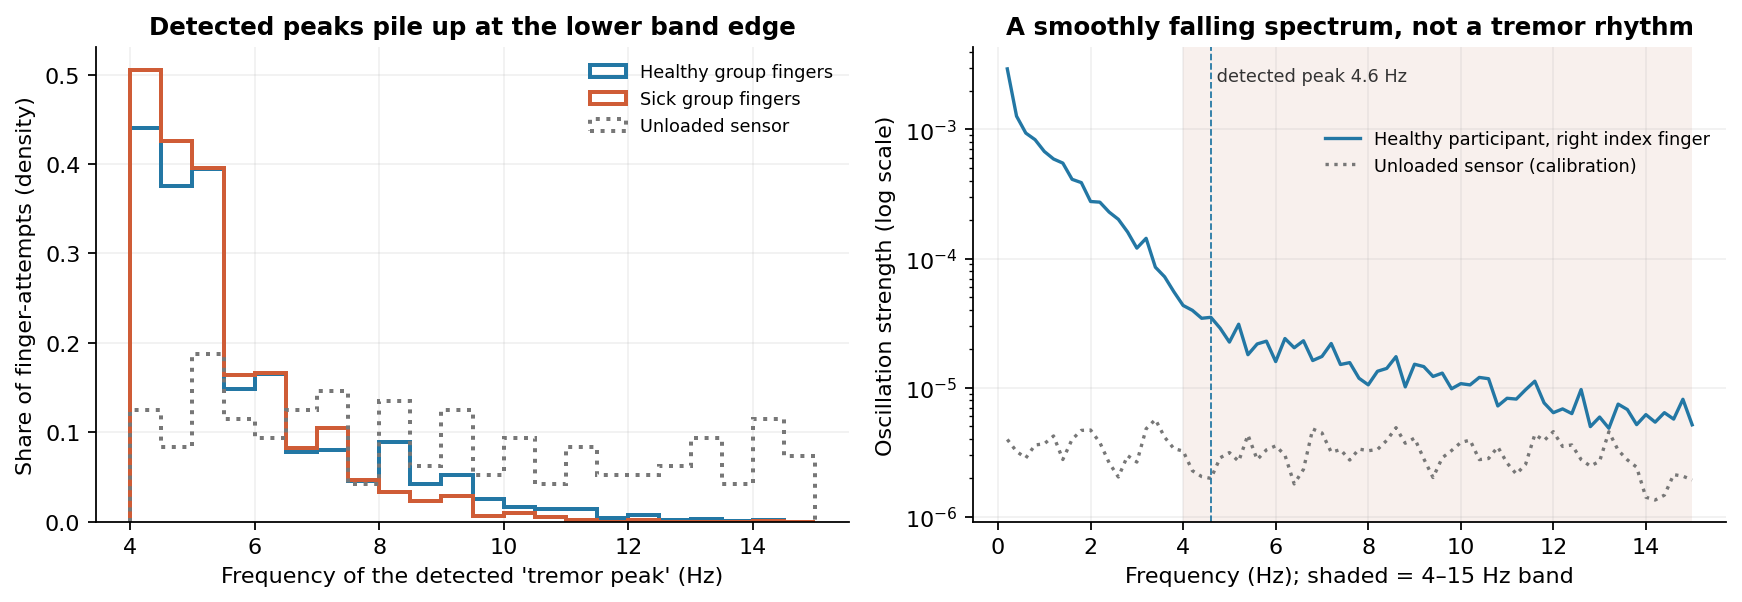

,finger_attempts,with_peak,peak_hz_q25,peak_hz_median,peak_hz_q75,share_peaks_below_6hz,prominence_median
source,,,,,,,
Healthy,2755,2755,4.6,5.2,6.4,0.680,2.652
Sick,3000,3000,4.4,5.0,6.0,0.745,3.160
Unloaded sensor,192,192,5.8,8.2,11.4,0.255,1.734


In [14]:
figure("08_peak_frequency_check")
display(R["peak_frequency_check"].set_index("source"))

The original analysis reports a "tremor peak" at about 5.2–5.6 Hz on every finger and in both groups. The check above shows why this should not be read as a tremor rhythm. In an unloaded sensor the detected peak lands anywhere between 4 and 15 Hz (median ≈ 8 Hz). In finger signals, about 70 % of detected peaks sit below 6 Hz, because the spectrum falls smoothly with frequency and the highest small bump is therefore usually near the lower edge of the band. The right panel shows a typical case: the "peak" at 4.6 Hz is a ripple on a falling curve. **A real tremor would appear as a clear hump above that falling background**, as in the week-2 teaching example (ILHC-BZCP, about 4–4.4 Hz). The peak frequency and its prominence should be recomputed relative to the falling background before being interpreted.

## Summary

In [15]:
c, pc, g = R["weak_hand_checks"], R["tremor_pattern_counts"].set_index("Pattern"), R["finger_group_ratio"]
s = R["age_summary"].set_index("Group")
say(f'''
| Question | Answer |
|---|---|
| Age, healthy vs sick | Median {s.loc['Healthy', 'Median age']:.0f} vs {s.loc['Sick', 'Median age']:.1f} years; only {s.loc['Healthy', 'Aged 50+']} healthy people are 50+. Age, recording period and game step all coincide with the group. |
| Sick participants barely using one hand | **{c['sick_below']} of {c['n_sick']}** below the healthy lower limit of hand symmetry ({c['threshold']:.2f}); range {c['sick_below_bootstrap_95'][0]}–{c['sick_below_bootstrap_95'][1]} under resampling. None completely silent; 0IKB-27Y1 effectively plays with one hand. |
| Do some fingers shake more? | Yes, consistently in both groups: thumb and little finger most, ring finger least. Part of this follows how hard each finger presses, but the order remains at equal force (sensor differences not excluded). |
| Sick vs healthy, per finger | Higher in the sick group on every finger, {g['ratio_sick_to_healthy'].min():.1f}–{g['ratio_sick_to_healthy'].max():.1f}× at age 50+; {int((g['p_holm'] < .05).sum())}/10 fingers significant after correction. The finger pattern is almost the same in both groups. |
| Within one person | Among people aged 50+: {pc.loc['localized (2–4 fingers)', 'Sick'] + pc.loc['generalized (5+ fingers)', 'Sick']} of {pc['Sick'].sum()} sick vs {pc['Healthy'].sum() - pc.loc['none', 'Healthy']} of {pc['Healthy'].sum()} healthy have 2+ elevated fingers. |
| Typical tremor frequency | Not established: the detected ~5 Hz peaks mostly reflect the falling spectrum. |
''')


| Question | Answer |
|---|---|
| Age, healthy vs sick | Median 23 vs 66.5 years; only 17 healthy people are 50+. Age, recording period and game step all coincide with the group. |
| Sick participants barely using one hand | **7 of 48** below the healthy lower limit of hand symmetry (0.62); range 6–10 under resampling. None completely silent; 0IKB-27Y1 effectively plays with one hand. |
| Do some fingers shake more? | Yes, consistently in both groups: thumb and little finger most, ring finger least. Part of this follows how hard each finger presses, but the order remains at equal force (sensor differences not excluded). |
| Sick vs healthy, per finger | Higher in the sick group on every finger, 1.2–2.0× at age 50+; 9/10 fingers significant after correction. The finger pattern is almost the same in both groups. |
| Within one person | Among people aged 50+: 21 of 40 sick vs 1 of 17 healthy have 2+ elevated fingers. |
| Typical tremor frequency | Not established: the detected ~5 Hz peaks mostly reflect the falling spectrum. |


### What this version changes compared with `analyza_prstov.ipynb`

| Topic | Original (Slovak) | This version |
|---|---|---|
| Healthy group | all 90 controls | 76 questionnaire-screened controls; 14 *other controls* excluded from comparisons |
| Reference for finger norms | controls aged 50+ (24, of whom 7 report a condition), each scored against a reference that includes themselves | healthy aged 50+ (17), leave-one-out |
| Patients compared with that reference | all ages | aged 50+ only |
| Weak-hand limit | 0.565 → 6 patients | 0.623 → 7 patients, with a resampling range and a raw-signal example |
| Most tremulous finger | little finger, by the fast/slow ratio | the ratio mainly tracks low force; force-adjusted amplitude still puts the little finger and the thumb first |
| Age | handled by restricting to 50+ | additionally shown that healthy amplitude does not rise with age |
| Peak frequency | ~5.4 Hz on all fingers | shown to come mostly from the falling spectrum |

### Limitations
- Labels: "healthy" is questionnaire-screened, not physician-confirmed; diagnoses, tremor ratings and medication of the sick group are unknown.
- Group membership coincides with age, recording period (Feb 2025 / Sep 2026 vs Mar–Aug 2025) and game-step ID, so group differences cannot be attributed to illness.
- Force is in uncalibrated device units; the sensor-to-finger mapping is inferred from force order, not verified; differences between fingers may partly be differences between sensors.
- The age-matched healthy reference is small (17 people), and the ring and middle fingers are close to the sensor noise.
- The 4–15 Hz amplitude also contains fast force corrections and transients (visible in the example above), not only involuntary tremor.